In [2]:
import pandas as pd

pd.set_option("display.max_columns", None)

df = pd.read_csv("../data/raw/hotel_bookings.csv")
df.head()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,3,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,4,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Direct,Direct,0,0,0,A,C,0,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Corporate,Corporate,0,0,0,A,A,0,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,0.0,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


In [4]:
# Tamanho
df.shape

(119390, 32)

In [5]:
# Tipos e nulos por coluna
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  str    
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  str    
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal                       

In [ ]:
# Número de nulos
df.isnull().sum()

hotel                                  0
is_canceled                            0
lead_time                              0
arrival_date_year                      0
arrival_date_month                     0
arrival_date_week_number               0
arrival_date_day_of_month              0
stays_in_weekend_nights                0
stays_in_week_nights                   0
adults                                 0
children                               4
babies                                 0
meal                                   0
country                              488
market_segment                         0
distribution_channel                   0
is_repeated_guest                      0
previous_cancellations                 0
previous_bookings_not_canceled         0
reserved_room_type                     0
assigned_room_type                     0
booking_changes                        0
deposit_type                           0
agent                              16340
company         

In [7]:
# Percentual de nulos
(df.isna().mean() * 100).round(2).sort_values(ascending=False)

company                           94.31
agent                             13.69
country                            0.41
hotel                              0.00
arrival_date_month                 0.00
arrival_date_week_number           0.00
lead_time                          0.00
is_canceled                        0.00
stays_in_weekend_nights            0.00
stays_in_week_nights               0.00
children                           0.00
adults                             0.00
babies                             0.00
meal                               0.00
arrival_date_day_of_month          0.00
arrival_date_year                  0.00
distribution_channel               0.00
market_segment                     0.00
previous_bookings_not_canceled     0.00
is_repeated_guest                  0.00
reserved_room_type                 0.00
assigned_room_type                 0.00
booking_changes                    0.00
previous_cancellations             0.00
deposit_type                       0.00


In [8]:
# Estatísticas das colunas numéricas
df.describe().T

,count,mean,std,min,25%,50%,75%,max
is_canceled,119390.0,0.370416,0.482918,0.00,0.00,0.000,1.0,1.0
lead_time,119390.0,104.011416,106.863097,0.00,18.00,69.000,160.0,737.0
arrival_date_year,119390.0,2016.156554,0.707476,2015.00,2016.00,2016.000,2017.0,2017.0
arrival_date_week_number,119390.0,27.165173,13.605138,1.00,16.00,28.000,38.0,53.0
arrival_date_day_of_month,119390.0,15.798241,8.780829,1.00,8.00,16.000,23.0,31.0
stays_in_weekend_nights,119390.0,0.927599,0.998613,0.00,0.00,1.000,2.0,19.0
stays_in_week_nights,119390.0,2.500302,1.908286,0.00,1.00,2.000,3.0,50.0
adults,119390.0,1.856403,0.579261,0.00,2.00,2.000,2.0,55.0
children,119386.0,0.103890,0.398561,0.00,0.00,0.000,0.0,10.0
babies,119390.0,0.007949,0.097436,0.00,0.00,0.000,0.0,10.0


In [30]:
# Valores únicos das colunas categóricas principais
for col in ["hotel", "meal", "market_segment", "distribution_channel", "deposit_type", "customer_type", "reservation_status"]:
    print(df[col].value_counts(dropna=False), "\n")

hotel
City Hotel      79330
Resort Hotel    40060
Name: count, dtype: int64 

meal
BB           92310
HB           14463
SC           10650
Undefined     1169
FB             798
Name: count, dtype: int64 

market_segment
Online TA        56477
Offline TA/TO    24219
Groups           19811
Direct           12606
Corporate         5295
Complementary      743
Aviation           237
Undefined            2
Name: count, dtype: int64 

distribution_channel
TA/TO        97870
Direct       14645
Corporate     6677
GDS            193
Undefined        5
Name: count, dtype: int64 

deposit_type
No Deposit    104641
Non Refund     14587
Refundable       162
Name: count, dtype: int64 

customer_type
Transient          89613
Transient-Party    25124
Contract            4076
Group                577
Name: count, dtype: int64 

reservation_status
Check-Out    75166
Canceled     43017
No-Show       1207
Name: count, dtype: int64 



In [10]:
# Duplicatas
df.duplicated().sum()

np.int64(31994)

In [40]:
dup = df[df.duplicated(keep=False)]
dup["market_segment"].value_counts()
dup["is_canceled"].value_counts()

is_canceled
1    23451
0    16714
Name: count, dtype: int64

In [12]:
# Diária negativa ou zero
df[df["adr"] <= 0].shape[0]

1960

In [39]:
# Diária igual a zero por segmento de mercado
df[df["adr"] == 0]["market_segment"].value_counts()

market_segment
Complementary    680
Online TA        367
Offline TA/TO    332
Groups           252
Direct           240
Corporate         82
Aviation           6
Name: count, dtype: int64

In [42]:
zero = df[df["adr"] == 0]
zero.groupby("market_segment")[["is_canceled"]].mean().round(2)
zero["reservation_status"].value_counts()

reservation_status
Check-Out    1746
Canceled      187
No-Show        26
Name: count, dtype: int64

In [13]:
# Reservas sem hóspedes
df[(df["adults"] + df["children"].fillna(0) + df["babies"]) == 0].shape[0]

180

In [14]:
# Reservas sem nenhuma noite
df[(df["stays_in_weekend_nights"] + df["stays_in_week_nights"]) == 0].shape[0]

715

In [41]:
sem_hospedes = (df["adults"] + df["children"].fillna(0) + df["babies"]) == 0
sem_noites = (df["stays_in_weekend_nights"] + df["stays_in_week_nights"]) == 0

df[sem_hospedes]["is_canceled"].value_counts()
df[sem_noites]["is_canceled"].value_counts()
df[sem_noites]["reservation_status"].value_counts()

reservation_status
Check-Out    680
Canceled      22
No-Show       13
Name: count, dtype: int64

In [37]:
# Outliers de diária
df["adr"].describe()
df.nlargest(5, "adr")[["hotel", "adr", "arrival_date_year", "arrival_date_month", "stays_in_weekend_nights", "stays_in_week_nights"]]

,hotel,adr,arrival_date_year,arrival_date_month,stays_in_weekend_nights,stays_in_week_nights
48515,City Hotel,5400.0,2016,March,0,1
111403,City Hotel,510.0,2017,May,0,1
15083,Resort Hotel,508.0,2015,July,0,1
103912,City Hotel,451.5,2016,December,1,1
13142,Resort Hotel,450.0,2017,August,4,10


In [16]:
import matplotlib.pyplot as plt
import seaborn as sns

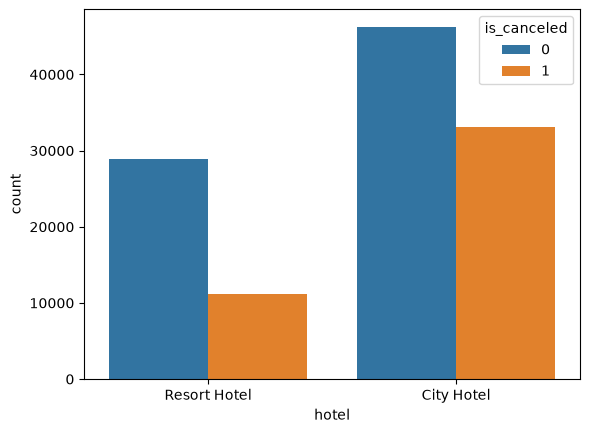

In [23]:
# Reservas por hotel e por status de cancelamento
sns.countplot(data=df, x="hotel", hue="is_canceled")
plt.show()

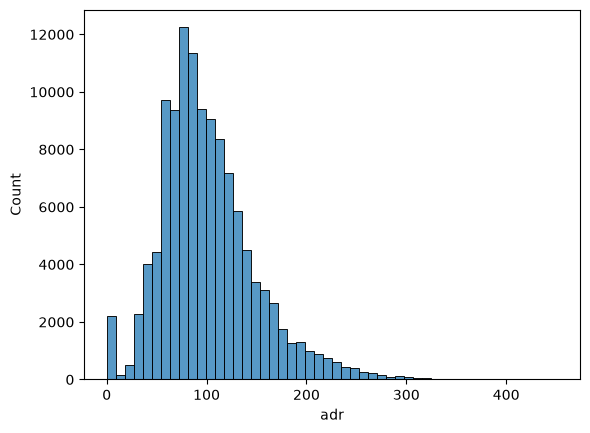

In [21]:
# Distribuição da diária (limitada para ver o formato)
sns.histplot(df[df["adr"].between(0, 500)]["adr"], bins=50)
plt.show()

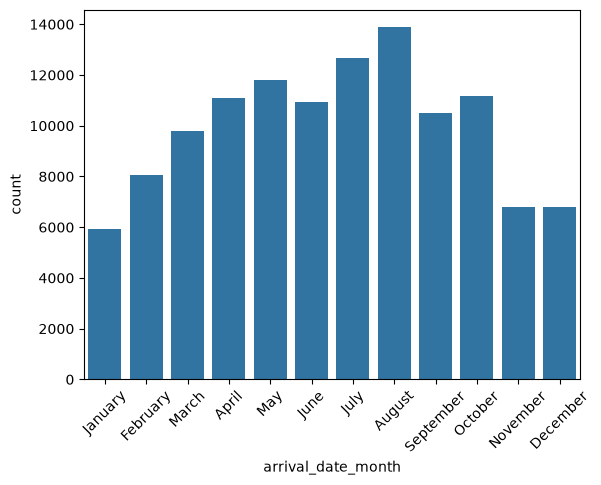

In [24]:
# Reservas por mês
ordem = ["January","February","March","April","May","June","July",
         "August","September","October","November","December"]
sns.countplot(data=df, x="arrival_date_month", order=ordem)
plt.xticks(rotation=45)
plt.show()

In [31]:
resumo = pd.DataFrame({
    "Coluna": df.columns,
    "Tipo": df.dtypes.astype(str).values,
    "Nulos (%)": (df.isna().mean() * 100).round(2).values,
})
resumo["Descrição"] = ""
resumo["Observações"] = ""

print(resumo.to_markdown(index=False))

| Coluna                         | Tipo    |   Nulos (%) | Descrição   | Observações   |
|:-------------------------------|:--------|------------:|:------------|:--------------|
| hotel                          | str     |        0    |             |               |
| is_canceled                    | int64   |        0    |             |               |
| lead_time                      | int64   |        0    |             |               |
| arrival_date_year              | int64   |        0    |             |               |
| arrival_date_month             | str     |        0    |             |               |
| arrival_date_week_number       | int64   |        0    |             |               |
| arrival_date_day_of_month      | int64   |        0    |             |               |
| stays_in_weekend_nights        | int64   |        0    |             |               |
| stays_in_week_nights           | int64   |        0    |             |               |
| adults             